In [27]:
from pathlib import Path
import tensorflow as tf
from functools import partial
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

In [15]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

SPLIT_DATASET_PATH = Path(
    r"D:\py\Eye-Disease-Detection-system\split_dataset"
)

class_names = [
    'normal',
    'cataract',
    'conjunctivitis',
    'pterygium'
]

train_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "train",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "val",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "test",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 2905 files belonging to 4 classes.
Found 623 files belonging to 4 classes.
Found 623 files belonging to 4 classes.


### Normaliztion


In [16]:
normalization_layer = tf.keras.layers.Rescaling(1./255)


### Data augmentation

In [17]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom((-0.15, 0.10)),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.15),
    tf.keras.layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="augmentation")


In [ ]:
NUM_CLASSES = 4  


# ------------------------------------------------------ default conv layer
# activation=None because BatchNorm goes between the conv and the ReLU.
DefaultConv2D = partial(
    tf.keras.layers.Conv2D,
    kernel_size=3,
    strides=1,
    padding="same",
    use_bias=False,
    kernel_initializer="he_normal",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4),
)


# --------------------------------------------------------- residual unit
@tf.keras.utils.register_keras_serializable()
class ResidualUnit(tf.keras.layers.Layer):
    def __init__(self, filters, strides=1, activation="relu", **kwargs):
        super().__init__(**kwargs)
        self.filters = filters
        self.strides = strides
        self.activation_name = activation
        self.activation = tf.keras.activations.get(activation)

        self.main_layers = [
            DefaultConv2D(filters, strides=strides),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Activation(activation),
            DefaultConv2D(filters),
            tf.keras.layers.BatchNormalization(),
        ]
        self.skip_layers = []
        if strides > 1:  # shape changes, so the skip path needs a 1x1 conv
            self.skip_layers = [
                DefaultConv2D(filters, kernel_size=1, strides=strides),
                tf.keras.layers.BatchNormalization(),
            ]

    def call(self, inputs):
        Z = inputs
        for layer in self.main_layers:
            Z = layer(Z)
        skip_Z = inputs
        for layer in self.skip_layers:
            skip_Z = layer(skip_Z)
        return self.activation(Z + skip_Z)

    def get_config(self):
        config = super().get_config()
        config.update({
            "filters": self.filters,
            "strides": self.strides,
            "activation": self.activation_name,
        })
        return config


# ----------------------------------------------------------------- model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    tf.keras.layers.Rescaling(1.0 / 255),

    # Stem: 224 -> 112
    DefaultConv2D(32, strides=2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),

    # 112 -> 56 -> 28 -> 14 -> 7
    ResidualUnit(64, strides=2),
    ResidualUnit(128, strides=2),
    ResidualUnit(256, strides=2),
    ResidualUnit(256, strides=2),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation="relu",
                          kernel_initializer="he_normal",
                          kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="eye_disease_resnet_small")

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"],
)

model.summary()

Model: "eye_disease_resnet_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_4 (ResidualUnit)  │ (None, 56, 56, 64)     │        58,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_5 (ResidualUnit)  │ (None, 28, 28, 128)    │       230,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_6 (ResidualUnit)  │ (None, 14, 14, 256)    │       920,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_7 (ResidualUnit)  │ (None, 7, 7, 256)      │     1,248,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,492,260 (9.51 MB)

 Trainable params: 2,487,972 (9.49 MB)

 Non-trainable params: 4,288 (16.75 KB)

In [19]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="../models/best_eye_disease_model_custom_model.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

In [20]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[checkpoint]

)

Epoch 1/30


d:\py\Eye-Disease-Detection-system\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 676ms/step - accuracy: 0.5053 - loss: 1.6947
Epoch 1: val_accuracy improved from None to 0.31461, saving model to ../models/best_eye_disease_model_custom_model.keras

Epoch 1: finished saving model to ../models/best_eye_disease_model_custom_model.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 70s 726ms/step - accuracy: 0.5053 - loss: 1.6947 - val_accuracy: 0.3146 - val_loss: 4.0913
Epoch 2/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 664ms/step - accuracy: 0.5752 - loss: 1.5198
Epoch 2: val_accuracy improved from 0.31461 to 0.35152, saving model to ../models/best_eye_disease_model_custom_model.keras

Epoch 2: finished saving model to ../models/best_eye_disease_model_custom_model.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 64s 700ms/step - accuracy: 0.5752 - loss: 1.5198 - val_accuracy: 0.3515 - val_loss: 2.1426
Epoch 3/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 704ms/step - accuracy: 0.6468 - loss: 1.4237
Epoch 3: val_accuracy improved from 0.35152 to 0.39968, saving model to ../models/best_eye_disease

In [21]:
model = tf.keras.models.load_model(
    "../models/best_eye_disease_model_custom_model.keras"
)

model.summary()

d:\py\Eye-Disease-Detection-system\.venv\Lib\site-packages\keras\src\layers\layer.py:442: UserWarning: `build()` was called on layer 'residual_unit_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
d:\py\Eye-Disease-Detection-system\.venv\Lib\site-packages\keras\src\layers\layer.py:442: UserWarning: `build()` was called on layer 'residual_unit_5', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
d:\py\Eye-Disease-Detection-system\.venv\Lib\site-packages\keras\src\layers\layer.py:442: UserWarning: `build(

Model: "eye_disease_resnet_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_4 (ResidualUnit)  │ (None, 56, 56, 64)     │        58,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_5 (ResidualUnit)  │ (None, 28, 28, 128)    │       230,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_6 (ResidualUnit)  │ (None, 14, 14, 256)    │       920,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_unit_7 (ResidualUnit)  │ (None, 7, 7, 256)      │     1,248,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,468,206 (28.49 MB)

 Trainable params: 2,487,972 (9.49 MB)

 Non-trainable params: 4,288 (16.75 KB)

 Optimizer params: 4,975,946 (18.98 MB)

In [22]:
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "../results/training_history.csv",
    index=False
)

In [23]:
test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 160ms/step - accuracy: 0.8700 - loss: 0.7960
Test Accuracy: 87.00%
Test Loss: 0.7960


In [24]:
# Actual labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_dataset
])

# Model predictions
y_pred_probs = model.predict(test_dataset)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=test_dataset.class_names,
    digits=4
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step
                precision    recall  f1-score   support

        normal     0.9344    0.8636    0.8976       132
      cataract     0.8989    0.9040    0.9014       177
conjunctivitis     0.8077    0.9742    0.8832       194
     pterygium     0.8876    0.6583    0.7560       120

      accuracy                         0.8700       623
     macro avg     0.8822    0.8500    0.8596       623
  weighted avg     0.8758    0.8700    0.8669       623



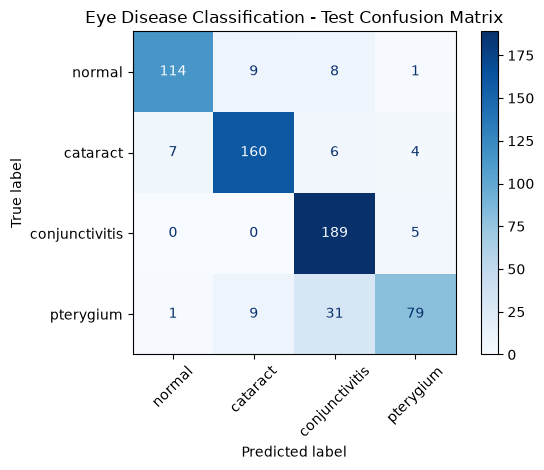

In [25]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(4)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Eye Disease Classification - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [26]:
Path("../results").mkdir(parents=True, exist_ok=True)

results = pd.DataFrame({
    "Metric": ["Test Accuracy", "Test Loss"],
    "Value": [test_accuracy, test_loss]
})

results.to_csv("../results/test_results.csv", index=False)